# REE measurement accuracy 


/opt/anaconda3/envs/chempath/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


[0.00028085]
[0.01235437]


/opt/anaconda3/envs/chempath/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


[0.00030797]
[0.01192471]


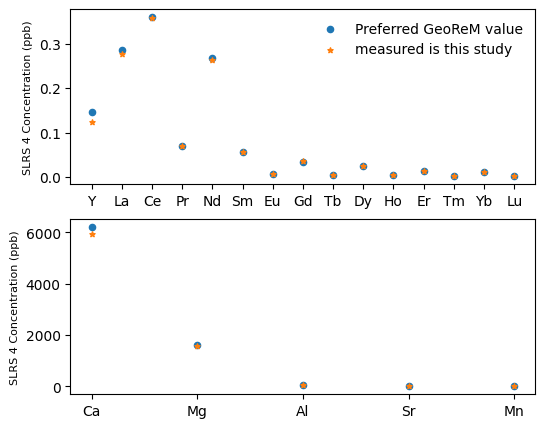

In [1]:
import numpy as np 
import os
os.chdir('data')
from utils import read_and_format_data
from reduce_nitric_acid_runs import *
import matplotlib.pyplot as plt


# SRLS 4 preffered values in ppb from https://www.georem.science/
SLRS_ref_vals = element_values = {
    "Li": 0.54,
    "Be": 0.007,
    "B": 5.95,
    "Na": 2400,
    "Mg": 1600,
    "Al": 54,
    "Si": 1864,
    "P": 9.13,
    "K": 680,
    "Ca": 6200,
    "Sc": 0.0113,
    "Ti": 1.46,
    "V": 0.32,
    "Cr": 0.33,
    "Mn": 3.37,
    "Fe": 103,
    "Co": 0.033,
    "Ni": 0.67,
    "Cu": 1.81,
    "Zn": 0.93,
    "Ga": 0.0119,
    "Ge": 0.01,
    "As": 0.68,
    "Se": 0.23,
    "Br": 47.8,
    "Rb": 1.53,
    "Sr": 26.3,
    "Y": 0.146,
    "Zr": 0.12,
    "Mo": 0.21,
    "Pd": 0.021,
    "Cd": 0.012,
    "Sb": 0.23,
    "Cs": 0.009,
    "Ba": 12.22,
    "La": 0.287,
    "Ce": 0.36,
    "Pr": 0.0693,
    "Nd": 0.269,
    "Sm": 0.0574,
    "Eu": 0.008,
    "Gd": 0.0342,
    "Tb": 0.0043,
    "Dy": 0.0242,
    "Ho": 0.0047,
    "Er": 0.0134,
    "Tm": 0.0017,
    "Yb": 0.012,
    "Lu": 0.0019,
    "W": 0.0133,
    "Tl": 0.0068,
    "Pb": 0.086,
    "Bi": 0.0021,
    "Th": 0.018,
    "U": 0.05,
}

ree = [ 
    "Y", "La", "Ce", "Pr", "Nd", "Sm", "Eu", "Gd", "Tb", "Dy", 
    "Ho", "Er", "Tm", "Yb", "Lu", 
]

major_els = [ 
    "Ca", "Mg", 'Al', 'Sr', 'Mn'
]

names_major=[    '44  Ca  [ No Gas ]',
    '25 -> 25  Mg  [ H2 ]',
    '27  Al  [ No Gas ]',
    '88  Sr  [ No Gas ]',
    '55 -> 55  Mn  [ H2 ]',]

names_ree = [
    '89  Y  [ No Gas ]',
    '89 -> 105  Y  [ O2 ]',
    '139  La  [ No Gas ]',
    '140  Ce  [ No Gas ]',
    '141  Pr  [ No Gas ]',
    '146  Nd  [ No Gas ]',
    '147  Sm  [ No Gas ]',
    '151  Eu  [ No Gas ]',
    '157  Gd  [ No Gas ]',
    '159  Tb  [ No Gas ]',
    '163  Dy  [ No Gas ]',
    '165  Ho  [ No Gas ]',
    '166  Er  [ No Gas ]',
    '169  Tm  [ No Gas ]',
    '172  Yb  [ No Gas ]',
    '175  Lu  [ No Gas ]',
    '151  Eu  [ No Gas ] oxide_corrected',
    '157  Gd  [ No Gas ] oxide_corrected'
    
]

# function to make a calibation curve withouth DF correction
def make_calibration_curves(data, var='CPS_In_normalized_HNO3', standards='new'):
    # read standards
    if standards == 'new':
        standards = read_standards202311_ppb()
    elif standards == 'old':
        standards = read_standards202309(with_Ca=False)

    # make ppm calibration curves
    data_std = data[data['Sample Name'].isin(standards.Name.unique())]
    standards = standards.rename(columns={'Name': 'Sample Name'})
    standards = standards.astype({'ppb':'float'})
    data_std = pd.merge(data_std, standards, on=['Sample Name', 'element'], 
        suffixes=('','_known'))
    data_std.ppb = data_std.ppb.fillna(0)
        
    def linear_fit_zero_interc_slope(element_description):
        data_std_el = data_std[data_std.element_description == element_description]
        if len(data_std_el.ppb) >= 2:
            a, _, _, _ = np.linalg.lstsq(data_std_el.ppb.to_numpy()[:,np.newaxis],
                data_std_el[var])
            return a[0]
        else:
            return np.nan

    data['zero_interc_slope'] = data.element_description.apply(
        linear_fit_zero_interc_slope)
    data['inferred_ppb_zero_intercept'] =\
        data[var]/data['zero_interc_slope']


# make calibration curves for run 5
run5 = read_and_format_data(run_number=5)
run5 = blank_correction(run5, var='CPS')
run5 = make_oxide_correction(run5, var='CPS_sample_blank_corrected')
run5 = normalize_to_In(run5, var='CPS_sample_blank_corrected')
make_calibration_curves(run5, var='CPS_In_normalized_sample')

# filter out SLRS 4 data
run5_slrs = run5[run5['Sample Name'] == 'SLRS 4']

# make calibration curves for run r
run6 = read_and_format_data(run_number=6)
run6 = blank_correction(run6, var='CPS')
run6 = make_oxide_correction(run6, var='CPS_sample_blank_corrected')
run6 = normalize_to_In(run6, var='CPS_sample_blank_corrected')
make_calibration_curves(run6, var='CPS_In_normalized_sample')

# filter out SLRS 4 data
run6_slrs = run6[run6['Sample Name'] == 'SLRS 4']

# get REE and major element data
run5_slrs_values_ree = run5_slrs[
    run5_slrs.element_description.isin(names_ree)][
        ['element', 'inferred_ppb_zero_intercept']
    ].set_index("element").to_dict()['inferred_ppb_zero_intercept']

run6_slrs_values_ree = run6_slrs[
    run6_slrs.element_description.isin(names_ree)][
        ['element', 'inferred_ppb_zero_intercept']
    ].set_index("element").to_dict()['inferred_ppb_zero_intercept']

run5_slrs_values_major = run5_slrs[
    run5_slrs.element_description.isin(names_major)][
        ['element', 'inferred_ppb_zero_intercept']
    ].set_index("element").to_dict()['inferred_ppb_zero_intercept']
run6_slrs_values_major = run6_slrs[
    run6_slrs.element_description.isin(names_major)][
        ['element', 'inferred_ppb_zero_intercept']
    ].set_index("element").to_dict()['inferred_ppb_zero_intercept']


# make arrays with REE data
run5_slrs_ = np.array([run5_slrs_values_ree[k] for k in ree])
run6_slrs_ = np.array([run6_slrs_values_ree[k] for k in ree])

# average values
average_ree_slrs = (run5_slrs_+ run6_slrs_) / 2

# make arrays with major element data
run5_slrs_major = np.array([run5_slrs_values_major[k] for k in major_els])
run6_slrs_major = np.array([run6_slrs_values_major[k] for k in major_els])

# average values
average_major_slrs = (run5_slrs_major+ run6_slrs_major) / 2


# make a plot
fig, axs = plt.subplots(2, 1, figsize=(6, 5))

# REE comparison
plt.sca(axs[0])
# plot preferred values from georem
plt.scatter(ree, [SLRS_ref_vals[k] for k in ree],
            label='Preferred GeoReM value', s=20)
# plot measured values
plt.scatter(ree, average_ree_slrs,
        label='measured is this study', s=15, marker='*')
plt.ylabel('SLRS 4 Concentration (ppb)', fontsize=8)
plt.legend(frameon=0)


# Major elemennt comparison
plt.sca(axs[1])
# plot preferred values from georem
plt.scatter(major_els, [SLRS_ref_vals[k] for k in major_els],
            label='Preferred GeoReM value', s=20)
# plot measured value
plt.scatter(major_els, average_major_slrs,
        label='Measured is this study', s=15, marker='*')
plt.ylabel('SLRS 4 Concentration (ppb)', fontsize=8)

plt.savefig('../plots/SLRS4.png',  bbox_inches='tight')


# I/(Ca+Mg) measurement acuracy

0
1
2
3


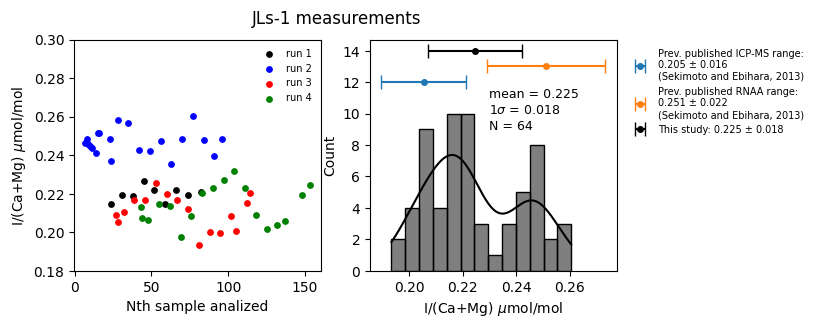

In [2]:
from reduce_stabilizer_runs import *
import matplotlib.pyplot as plt
import seaborn as sns

# read iodine raw data
run8 = read_and_format_data(run_number=8)
run9 = read_and_format_data(run_number=9)
run10 = read_and_format_data(run_number=10)
run11 = read_and_format_data(run_number=11)


# function for iodine detection limit
def add_iodine_cutoff_values(run, run_num):
    # find drift solution samples for run
    drift_solution = 'JLs-1 May 30, 2024'
    if run_num == 10:
        drift_solution = 'JLs-1 June 5, 2024'
    if run_num == 11:
        drift_solution = 'JLs-1 June 6, 2024'
    
    # if drift_correction:
        # run = make_drift_correction(run)
    if run_num == 9:
        blank1_run_num = run.loc[run['Sample Name'] == 'blank-2'].iloc[0].run_number
    else:
        blank1_run_num = run.loc[run['Sample Name'] == 'blank-1'].iloc[0].run_number
        run = run[run['run_number'] >= blank1_run_num]
    
    drift = run[run['Sample Name'] == drift_solution]
    # drift = drift[drift['run_number'] > blank1_run_num]
    # find sigma of iodine concentration
    drift = drift[drift['element'] == 'I']
    conc = 'CPS_driftc'
    std = drift[conc].std()
    # cutoff = max_sample_blank + 2 sigma
    max_sample_blank = run[(run.is_sample_blank)&(run.element=='I')][conc].max()
    cutoff = max_sample_blank + 3*std

    run['iodine_cutoff'] = cutoff
    iodine_data = run[run.element=='I'][['complete_sample_name', conc]]
    iodine_data = iodine_data.rename(columns={conc: 'iodine_cps'})
    run = pd.merge(run, iodine_data, on='complete_sample_name', how='left')
    run['has_iodine'] = run['iodine_cps'] > run['iodine_cutoff']
    
    return run

# function to calculate precission
def add_precision(run, run_num):
    drift_solution = 'JLs-1 May 30, 2024'
    if run_num == 10:
        drift_solution = 'JLs-1 June 5, 2024'
    if run_num == 11:
        drift_solution = 'JLs-1 June 6, 2024'
    drift = run[run['Sample Name']==drift_solution]
    drift = drift[drift.element=='I']
    std_raw = drift['CPS'].std()
    mean_raw = drift['CPS'].mean()
    std_corr = drift['CPS_driftc_intstdc_sample_blank_corrected'].std()
    mean_corr = drift['CPS_driftc_intstdc_sample_blank_corrected'].mean()
    run['drift_precision_corr'] = std_corr/mean_corr
    run['drift_precision_raw'] = std_raw/mean_raw
    return run

# function to reduce raw icmps data
def find_concentrations(run, run_number):
    run = read_and_format_data(run_number=run_number)
    run = make_drift_correction(run, run_number, var='CPS')
    run = make_internal_standard_correction(run, var='CPS_driftc')
    run = blank_correction(run, var='CPS_driftc_intstdc')
    run = normalize_to_Ca_Mg_iodine_runs(run, var='CPS_driftc_intstdc_sample_blank_corrected')
    run = make_calibration_curves(run, run_number, var='CPS_driftc_intstdc_sample_blank_corrected_CaMgnorm')
    run = add_iodine_cutoff_values(run, run_number)
    run = add_precision(run, run_number)
    run['run_id'] = str(run_number)
    return run
        

# reduce raw icpms data
runs_list = [run8, run9, run10, run11]
run_numbers = [8,9,10,11]
runl = [find_concentrations(run, run_numbers[i]) for i, run in 
    enumerate(runs_list)]
runs = pd.concat(runl)

# assign formation names to samples
def starts_with_num(x):
    try:
        int(x[0])
    except:
        return False
    return True

def assign_formation(sample_name):
    if sample_name.startswith('SR'):
        return 'Steep Rock'
    elif sample_name.startswith('B'):
        return 'Gordon Lake'
    elif starts_with_num(sample_name) and 'Stabilizer' not in sample_name:
        return 'Espanola'
    else:
        return 'Not sample'
        
# assign formation names
runs['formation'] = runs['Sample Name'].apply(assign_formation)




fig, axs = plt.subplots(1,2, figsize=(7,3))

# function to calculate I/(Ca+Mg) in micromol/mol from previously published
# values
def calculate_I_CaMg_ratio(I_ppb, I_unc_ppb,
                           CaO_wt=55.09,
                           MgO_wt=0.606):

    # Molecular weights (g/mol)
    MW_CaO = 56.077
    MW_MgO = 40.304
    MW_I = 126.904

    # wt% -> ppb
    CaO_ppb = CaO_wt * 1e7
    MgO_ppb = MgO_wt * 1e7

    # ppb -> g/kg
    CaO_gkg = CaO_ppb * 1e-6
    MgO_gkg = MgO_ppb * 1e-6
    I_gkg = I_ppb * 1e-6
    I_unc_gkg = I_unc_ppb * 1e-6

    # g/kg -> mol/kg
    Ca_molkg = CaO_gkg / MW_CaO
    Mg_molkg = MgO_gkg / MW_MgO
    I_molkg = I_gkg / MW_I
    I_unc_molkg = I_unc_gkg / MW_I

    # Total Ca + Mg
    CaMg_molkg = Ca_molkg + Mg_molkg

    # I/(Ca+Mg)
    ratio = I_molkg / CaMg_molkg
    ratio_unc = I_unc_molkg / CaMg_molkg

    # mol/mol -> μmol/mol
    ratio_umolmol = ratio * 1e6
    ratio_unc_umolmol = ratio_unc * 1e6

    return ratio_umolmol, ratio_unc_umolmol

# jls1 values from https://doi.org/10.1021/ac400637d
ICaMg_icpms_mumolmol, ICaMg_icpms_unc_mumolmol = calculate_I_CaMg_ratio(260, 20)
ICaMg_rnaa_mumolmol, ICaMg_rnaa_unc_mumolmol = calculate_I_CaMg_ratio(318, 28)



colors = ['k', 'b', 'r', 'g']
labels = ['run 1', 'run 2', 'run 3', 'run 4']
# names of jls1 solution in each run
jls1_names = ['JLs-1 May 30, 2024', 'JLs-1 May 30, 2024', 'JLs-1 June 5, 2024', 
    'JLs-1 June 6, 2024']

# plot jls1 measuremnts
plt.sca(axs[0])
jls_vals = []
for i, run in enumerate(runl):
    print(i)
    jls1_name = jls1_names[i]
    # run_ = run[run.element_description == '25  Mg  [ No Gas solution ]']
    run_ = run[run.element=='I']
    

    run_jls = run_[run_['Sample Name']==jls1_name]
    run_jlsmay = run_[run_['Sample Name'] == 'JLs-1 May 30, 2024']
    run_cal1 = run_[run_['Sample Name'] == 'Cal 1']


    plt.scatter(run_jls.run_number, run_jls['inferred_mol/mol'] * 1e6 , label=labels[i],
            color=colors[i], s=15)
    jls_vals.append(run_jls['inferred_mol/mol'])

jls_vals = pd.concat(jls_vals)

# plt.ylabel('JLS1 I/(Ca+Mg) mol/mol')
plt.ylabel(r'I/(Ca+Mg) $\mu$mol/mol')
plt.xlabel('Nth sample analized')
plt.legend(fontsize=7, frameon=0)
plt.ylim(0.18, 0.3)

# compare to previously published values
plt.sca(axs[1])
mean = np.mean(jls_vals * 1e6)
std = np.std(jls_vals * 1e6)

sns.histplot(jls_vals * 1e6, bins=13, kde=True, color='k')

# Published ICP-MS value
plt.errorbar(
    ICaMg_icpms_mumolmol, 12,
    xerr=ICaMg_icpms_unc_mumolmol,
    fmt='o',
    capsize=5,
    markersize=4,
    label='Prev. published ICP-MS range:\n'+ f'{ICaMg_icpms_mumolmol:.3f} ± {ICaMg_icpms_unc_mumolmol:.3f}'+'\n(Sekimoto and Ebihara, 2013)'
)

# Published RNAA value
plt.errorbar(
    ICaMg_rnaa_mumolmol, 13,
    xerr=ICaMg_rnaa_unc_mumolmol,
    fmt='o',
    capsize=5,
    markersize=4,
    label='Prev. published RNAA range:\n'+ f'{ICaMg_rnaa_mumolmol:.3f} ± {ICaMg_rnaa_unc_mumolmol:.3f}'+'\n(Sekimoto and Ebihara, 2013)'
)

# Our mean ± 1 SD
plt.errorbar(
    mean, 14,
    xerr=std,
    fmt='o',
    capsize=5,
    markersize=4,
    label=f'This study: {mean:.3f} ± {std:.3f}',
    color='k'
)

plt.xlabel(r'I/(Ca+Mg) $\mu$mol/mol')
plt.ylabel('Count')

plt.legend(
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    fontsize=7,
    frameon=0
)

plt.text(.23, 11, f'mean = {round(mean, 3)}', fontsize=9, color='black') 
plt.text(.23, 10, r'1$\sigma$'+f' = {round(std, 3)}', fontsize=9, color='k') 
plt.text(.23, 9, r'N = '+f'{len(jls_vals)}', fontsize=9, color='k') 
plt.suptitle('JLs-1 measurements')
plt.savefig('../plots/jls1_ICaMg.png',  bbox_inches='tight')